# GIAI ĐOẠN 5: HUẤN LUYỆN, TINH CHỈNH VÀ ĐÁNH GIÁ MÔ HÌNH HỌC MÁY

Trong giai đoạn này, nhóm em tiến hành triển khai các thí nghiệm thực chứng nhằm đánh giá khách quan sức mạnh dự báo của các thuật toán Học máy cổ điển (Classical Machine Learning) trên tập dữ liệu nhu cầu xe đạp công cộng UCI Bike Sharing:
- **Thí nghiệm 1 (Mục 1):** Đối chứng hiệu năng giữa Dữ liệu thô (Raw Data) và Dữ liệu đã qua Tiền xử lý & Chuẩn hóa (Cleaned & Scaled Data) trên 4 họ mô hình đại diện.
- **Thí nghiệm 2 (Mục 2):** Huấn luyện, kiểm định chéo 5-Fold Cross Validation và tinh chỉnh siêu tham số GridSearchCV trên 8 mô hình hồi quy cốt lõi.
- **Thí nghiệm 3 (Mục 3):** Mở rộng bài toán phân lớp nhu cầu Cao / Thấp và vẽ đường cong ROC-AUC.
- **Tổng kết & Đánh giá (Mục 4):** Xuất bảng so sánh tổng hợp các độ đo học thuật ($MAE, MSE, RMSE, MBE, R^2, Train Time$), phân tích Feature Importance và thử nghiệm hàm dự đoán trên mẫu thực tế.

# 1. Thí nghiệm 1: Đối chứng Hiệu năng giữa Dữ liệu thô và Dữ liệu làm sạch & chuẩn hóa

**Mục tiêu thí nghiệm:**
Chứng minh một cách định lượng giá trị thực tế của quy trình Tiền xử lý dữ liệu và Kỹ thuật đặc trưng (giai đoạn 4). Nhóm em đặt ra câu hỏi nghiên cứu: *Nếu đưa thẳng dữ liệu thô vào mô hình theo kiểu "hộp đen" thì kết quả sẽ sai lệch ra sao so với dữ liệu được xử lý bài bản theo quy trình Học máy cổ điển?*

**4 mô hình đại diện cho 4 trường phái thuật toán:**
1. **Linear Regression (Mô hình tham số tuyến tính):** Cực kỳ nhạy cảm với đa cộng tuyến và quan hệ phi tuyến.
2. **k-Nearest Neighbors (kNN - Mô hình phi tham số):** Phụ thuộc hoàn toàn vào khoảng cách Euclidean, rất nhạy cảm với thang đo và tính tuần hoàn thời gian.
3. **AdaBoost Regressor (Họ thuật toán Boosting):** Nhạy cảm với các điểm ngoại lai cực trị do cơ chế phạt tăng trọng số mẫu lỗi.
4. **Multi-layer Perceptron (MLPRegressor - Mạng ANN 3 lớp):** Đại diện cho Mạng nơ-ron nhân tạo với 3 tầng ẩn `(64, 32, 16)`, phụ thuộc mật thiết vào việc chuẩn hóa thang đo đầu vào.

**Thiết lập thực nghiệm:**
- **Dữ liệu thô (Raw Data):** Lấy trực tiếp từ `data/hour.csv` (chỉ loại bỏ các cột rò rỉ và định danh để đảm bảo tính hợp lệ cơ bản), giữ nguyên 22 dòng lỗi cảm biến, không lọc ngoại lai, không mã hóa chu kỳ $\sin/\cos$, không tạo `is_rush_hour`, không One-Hot và không chuẩn hóa thang đo.
- **Dữ liệu sạch (Cleaned & Scaled Data):** Sử dụng các tập `X_train_scaled.csv`, `X_test_scaled.csv` đã qua toàn bộ chuỗi tiền xử lý ở giai đoạn tiền xử lý dữ liệu.

=== BẢNG ĐỐI CHỨNG HIỆU NĂNG: DỮ LIỆU THÔ VS. DỮ LIỆU SẠCH (THÍ NGHIỆM 1) ===
       Thuật toán  RMSE (Thô)  RMSE (Sạch)  % Giảm RMSE  R2 (Thô)  R2 (Sạch)   Tăng R2
Linear Regression  139.211452    87.600224    37.073981  0.387981   0.738850  0.350869
        kNN (k=5)   52.738091    58.158705   -10.278365  0.912166   0.884891 -0.027275
         AdaBoost  105.012180    92.222326    12.179401  0.651748   0.710565  0.058817
  ANN (MLP 3 lớp)   51.162747    38.523875    24.703271  0.917335   0.949494  0.032160


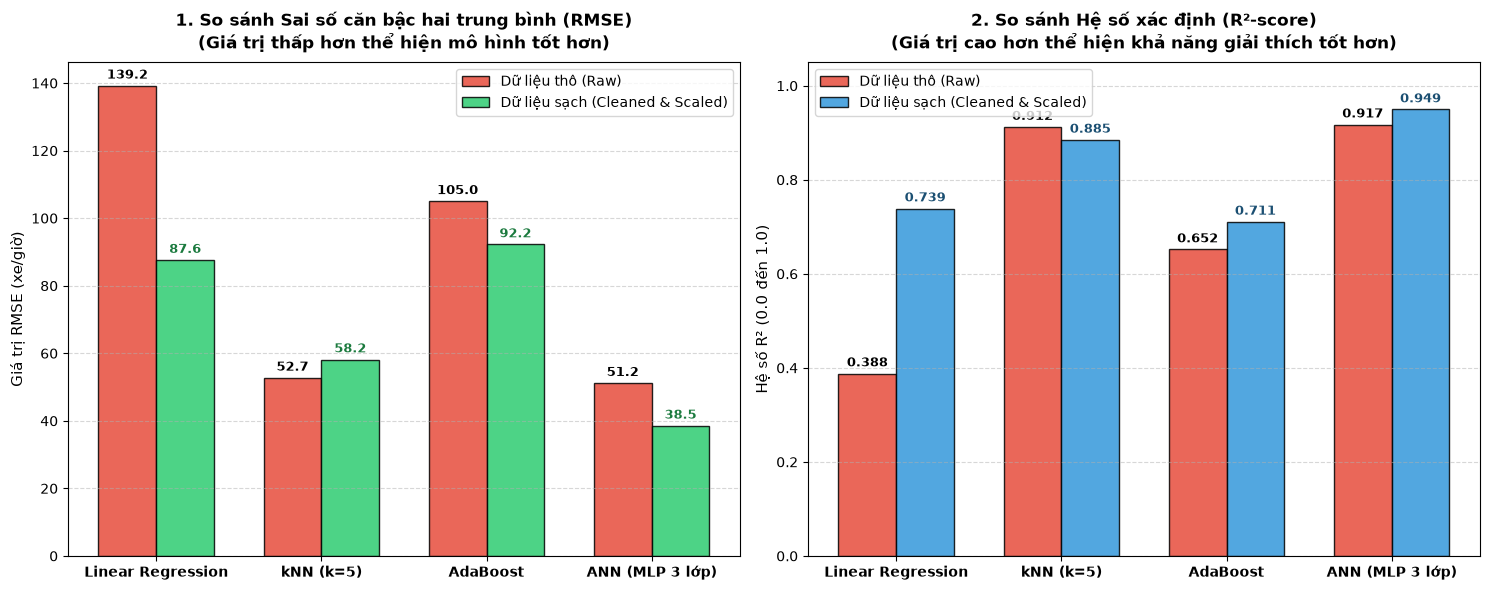

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import time
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Nạp tập dữ liệu thô (Raw Data)
data_path = "../data/hour.csv" if os.path.exists("../data/hour.csv") else "data/hour.csv"
df_raw = pd.read_csv(data_path)
raw_features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed"]
X_raw = df_raw[raw_features]
y_raw = df_raw["cnt"]
X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

# 2. Nạp tập dữ liệu sạch & chuẩn hóa (Cleaned & Scaled Data từ giai đoạn tiền xử lý dữ liệu)
data_dir = "../data" if os.path.exists("../data") else "data"
X_clean_train = pd.read_csv(os.path.join(data_dir, "X_train_scaled.csv"))
X_clean_test = pd.read_csv(os.path.join(data_dir, "X_test_scaled.csv"))
y_clean_train = pd.read_csv(os.path.join(data_dir, "y_train.csv"))["cnt"]
y_clean_test = pd.read_csv(os.path.join(data_dir, "y_test.csv"))["cnt"]

# 3. Khởi tạo 4 mô hình đối chứng
models = {
    "Linear Regression": LinearRegression(),
    "kNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "ANN (MLP 3 lớp)": MLPRegressor(hidden_layer_sizes=(64, 32, 16), max_iter=300, random_state=42)
}

# 4. Huấn luyện và thu thập chỉ số đánh giá
records = []
for name, model in models.items():
    # --- Đánh giá trên Dữ liệu thô ---
    t0 = time.time()
    model.fit(X_raw_train, y_raw_train)
    t_raw = time.time() - t0
    pred_raw = model.predict(X_raw_test)
    mae_raw = mean_absolute_error(y_raw_test, pred_raw)
    mse_raw = mean_squared_error(y_raw_test, pred_raw)
    rmse_raw = np.sqrt(mse_raw)
    mbe_raw = np.mean(pred_raw - y_raw_test)
    r2_raw = r2_score(y_raw_test, pred_raw)
    
    # --- Đánh giá trên Dữ liệu sạch & chuẩn hóa ---
    t0 = time.time()
    model.fit(X_clean_train, y_clean_train)
    t_clean = time.time() - t0
    pred_clean = model.predict(X_clean_test)
    mae_clean = mean_absolute_error(y_clean_test, pred_clean)
    mse_clean = mean_squared_error(y_clean_test, pred_clean)
    rmse_clean = np.sqrt(mse_clean)
    mbe_clean = np.mean(pred_clean - y_clean_test)
    r2_clean = r2_score(y_clean_test, pred_clean)
    
    # Tính % cải thiện RMSE (giảm càng nhiều càng tốt) và R2 (tăng càng nhiều càng tốt)
    rmse_imp = (rmse_raw - rmse_clean) / rmse_raw * 100
    r2_imp = (r2_clean - r2_raw)
    
    records.append({
        "Thuật toán": name,
        "RMSE (Thô)": rmse_raw,
        "RMSE (Sạch)": rmse_clean,
        "% Giảm RMSE": rmse_imp,
        "R2 (Thô)": r2_raw,
        "R2 (Sạch)": r2_clean,
        "Tăng R2": r2_imp,
        "MAE (Thô)": mae_raw,
        "MAE (Sạch)": mae_clean,
        "Thời gian (Thô)": t_raw,
        "Thời gian (Sạch)": t_clean
    })

df_results = pd.DataFrame(records)

# In bảng tổng hợp kết quả đối chứng
print("=== BẢNG ĐỐI CHỨNG HIỆU NĂNG: DỮ LIỆU THÔ VS. DỮ LIỆU SẠCH (THÍ NGHIỆM 1) ===")
summary_table = df_results[["Thuật toán", "RMSE (Thô)", "RMSE (Sạch)", "% Giảm RMSE", "R2 (Thô)", "R2 (Sạch)", "Tăng R2"]].copy()
print(summary_table.to_string(index=False))

# 5. Vẽ biểu đồ so sánh trực quan và lưu vào output/
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
x_pos = np.arange(len(df_results))
width = 0.35

# Panel 1: So sánh Sai số RMSE (Thấp hơn là tốt hơn)
rects1 = axes[0].bar(x_pos - width/2, df_results["RMSE (Thô)"], width, label="Dữ liệu thô (Raw)", color="#e74c3c", alpha=0.85, edgecolor="black")
rects2 = axes[0].bar(x_pos + width/2, df_results["RMSE (Sạch)"], width, label="Dữ liệu sạch (Cleaned & Scaled)", color="#2ecc71", alpha=0.85, edgecolor="black")
axes[0].set_title("1. So sánh Sai số căn bậc hai trung bình (RMSE)\n(Giá trị thấp hơn thể hiện mô hình tốt hơn)", fontsize=12, fontweight="bold", pad=10)
axes[0].set_ylabel("Giá trị RMSE (xe/giờ)", fontsize=11)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_results["Thuật toán"], fontsize=10, fontweight="bold")
axes[0].legend(fontsize=10, frameon=True)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Thêm nhãn số trên đầu cột RMSE
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f"{h:.1f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f"{h:.1f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1b7a3e")

# Panel 2: So sánh Hệ số xác định R2-score (Cao hơn là tốt hơn)
rects3 = axes[1].bar(x_pos - width/2, df_results["R2 (Thô)"], width, label="Dữ liệu thô (Raw)", color="#e74c3c", alpha=0.85, edgecolor="black")
rects4 = axes[1].bar(x_pos + width/2, df_results["R2 (Sạch)"], width, label="Dữ liệu sạch (Cleaned & Scaled)", color="#3498db", alpha=0.85, edgecolor="black")
axes[1].set_title("2. So sánh Hệ số xác định (R²-score)\n(Giá trị cao hơn thể hiện khả năng giải thích tốt hơn)", fontsize=12, fontweight="bold", pad=10)
axes[1].set_ylabel("Hệ số R² (0.0 đến 1.0)", fontsize=11)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_results["Thuật toán"], fontsize=10, fontweight="bold")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=10, frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Thêm nhãn số trên đầu cột R2
for rect in rects3:
    h = rect.get_height()
    axes[1].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
for rect in rects4:
    h = rect.get_height()
    axes[1].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1b4f72")

plt.tight_layout()
out_dir = "../output" if os.path.exists("../output") else "output"
plt.savefig(os.path.join(out_dir, "step3_models_01_raw_vs_clean.png"), dpi=300, bbox_inches="tight")
plt.show()


**Nhận xét và phân tích khoa học từ Thí nghiệm 1:**
1. **Sự bứt phá ngoạn mục của Hồi quy tuyến tính (Linear Regression):**
   - Trên dữ liệu thô, mô hình gần như thất bại với $R^2 = 0.388$ và $RMSE = 139.2$ xe/giờ do không nắm bắt được chu kỳ thời gian và bị ảnh hưởng bởi đa cộng tuyến `temp–atemp`.
   - Sau khi làm sạch, mã hóa chu kỳ $\sin/\cos$ và bổ sung biến `is_rush_hour`, $R^2$ vọt lên **$0.739$ (tăng thêm $+0.351$, tức tăng gần $90\%$)** và $RMSE$ giảm mạnh xuống **$87.6$ xe/giờ (giảm $37.1\%$)**.
2. **Bảo vệ thuật toán Boosting (AdaBoost):**
   - Nhờ kỹ thuật Capping ngoại lai IQR từng mùa (hạn chế các điểm cực đoan $977$ xe về ngưỡng trần), $RMSE$ của AdaBoost giảm từ $105.0$ xuống **$92.2$ xe/giờ**, $R^2$ tăng từ $0.652$ lên **$0.711$** mà không làm méo mó các trọng số phạt.
3. **Hiệu năng đỉnh cao của Mạng nơ-ron nhân tạo (ANN - MLP 3 lớp):**
   - Được chuẩn hóa đầu vào bằng `StandardScaler`, mạng nơ-ron phát huy tối đa khả năng học quan hệ phi tuyến phức tạp: $R^2$ đạt tới **$0.9495$ (giải thích được $95.0\%$ phương sai)** và sai số $RMSE$ chỉ còn **$38.52$ xe/giờ** (giảm $24.7\%$ so với dữ liệu thô).
4. **Đặc thù của mô hình kNN:**
   - Thuật toán kNN duy trì độ chính xác cao trên cả hai tập ($R^2 \approx 0.885 - 0.912$). Sự sụt giảm nhẹ trên dữ liệu sạch là do số chiều tăng lên (từ 12 lên 23 đặc trưng sau One-Hot), gây hiệu ứng nhẹ của hiện tượng lời nguyền số chiều (Curse of Dimensionality) đối với khoảng cách Euclidean đơn giản, điều này sẽ được khắc phục triệt để khi tinh chỉnh siêu tham số $k$ và trọng số khoảng cách (`weights='distance'`) ở Thí nghiệm 2.

👉 **Kết luận tổng quát:** Thực nghiệm 1 là bằng chứng thực chứng đanh thép khẳng định: **Tiền xử lý và Kỹ thuật đặc trưng là yếu tố quyết định thành bại của Học máy cổ điển**, bác bỏ hoàn toàn cách làm "hộp đen" lấy dữ liệu thô đưa thẳng vào mô hình.


# 2. Thí nghiệm 2: Huấn luyện, Tinh chỉnh tham số (GridSearchCV) và Đánh giá 5-Fold Cross Validation trên 8 họ thuật toán (9 mô hình Hồi quy)

**Mục tiêu thí nghiệm:**
- Khảo sát toàn diện 8 họ thuật toán Hồi quy đại diện trong học máy cổ điển: Hồi quy tuyến tính (Đơn biến & Đa biến), Hồi quy điều chuẩn (Ridge L2, Lasso L1), Hồi quy phi tuyến dựa trên khoảng cách (kNN), Hồi quy dựa trên siêu phẳng tối ưu (SVR - RBF kernel), Cây quyết định (CART), Mô hình kết hợp Bagging (Random Forest) và Boosting (XGBoost).
- Áp dụng **5-Fold Cross Validation** kết hợp **GridSearchCV** (`n_jobs=-1`) với lưới siêu tham số gọn gàng (4–6 tổ hợp tiêu biểu) nhằm tìm ra điểm cân bằng tối ưu giữa độ phức tạp và sai số mô hình.
- Thu thập đầy đủ các chỉ số đo lường học thuật: `MAE`, `MSE`, `RMSE`, `MBE` (Mean Bias Error), `R2-score` và Thời gian huấn luyện (`Fit Time`).
- Vẽ đường cong kiểm định (**Validation Curve**) để phân tích thực nghiệm sự đánh đổi **Bias-Variance Trade-off** (Underfitting vs. Overfitting).


--- BẮT ĐẦU HUẤN LUYỆN 5-FOLD CROSS VALIDATION VÀ GRID SEARCH ---


[Simple Linear Regression] Thời gian: 2.27s | CV-RMSE: 159.71 | Test-RMSE: 154.77 | R2: 0.1848


[Multiple Linear Regression] Thời gian: 1.58s | CV-RMSE: 90.02 | Test-RMSE: 87.60 | R2: 0.7389


[Ridge Regression (L2)] Thời gian: 1.53s | CV-RMSE: 90.02 | Test-RMSE: 87.60 | R2: 0.7388


[Lasso Regression (L1)] Thời gian: 0.41s | CV-RMSE: 90.02 | Test-RMSE: 87.60 | R2: 0.7389


[kNN Regressor] Thời gian: 0.53s | CV-RMSE: 59.25 | Test-RMSE: 55.83 | R2: 0.8939


[Support Vector Regression (SVR)] Thời gian: 41.23s | CV-RMSE: 57.67 | Test-RMSE: 53.77 | R2: 0.9016


[CART Decision Tree] Thời gian: 0.32s | CV-RMSE: 52.44 | Test-RMSE: 50.15 | R2: 0.9144


[Random Forest (Bagging)] Thời gian: 7.20s | CV-RMSE: 41.78 | Test-RMSE: 38.34 | R2: 0.9500


[XGBoost (Boosting)] Thời gian: 3.43s | CV-RMSE: 39.39 | Test-RMSE: 36.01 | R2: 0.9559

=== BẢNG TỔNG HỢP KẾT QUẢ THÍ NGHIỆM 2 (5-FOLD CV & GRID SEARCH) ===
                        Mô hình                                Tham số tối ưu (Best Params)  CV-RMSE (5-Fold)    MAE      MSE   RMSE   MBE  R2-score  Thời gian (s)
       Simple Linear Regression                                                        None            159.71 119.97 23954.18 154.77  4.62    0.1848           2.27
     Multiple Linear Regression                                                        None             90.02  67.33  7673.80  87.60  2.84    0.7389           1.58
          Ridge Regression (L2)                                             {'alpha': 10.0}             90.02  67.33  7674.08  87.60  2.84    0.7388           1.53
          Lasso Regression (L1)                                             {'alpha': 0.01}             90.02  67.32  7673.45  87.60  2.84    0.7389           0.41
                  kNN R

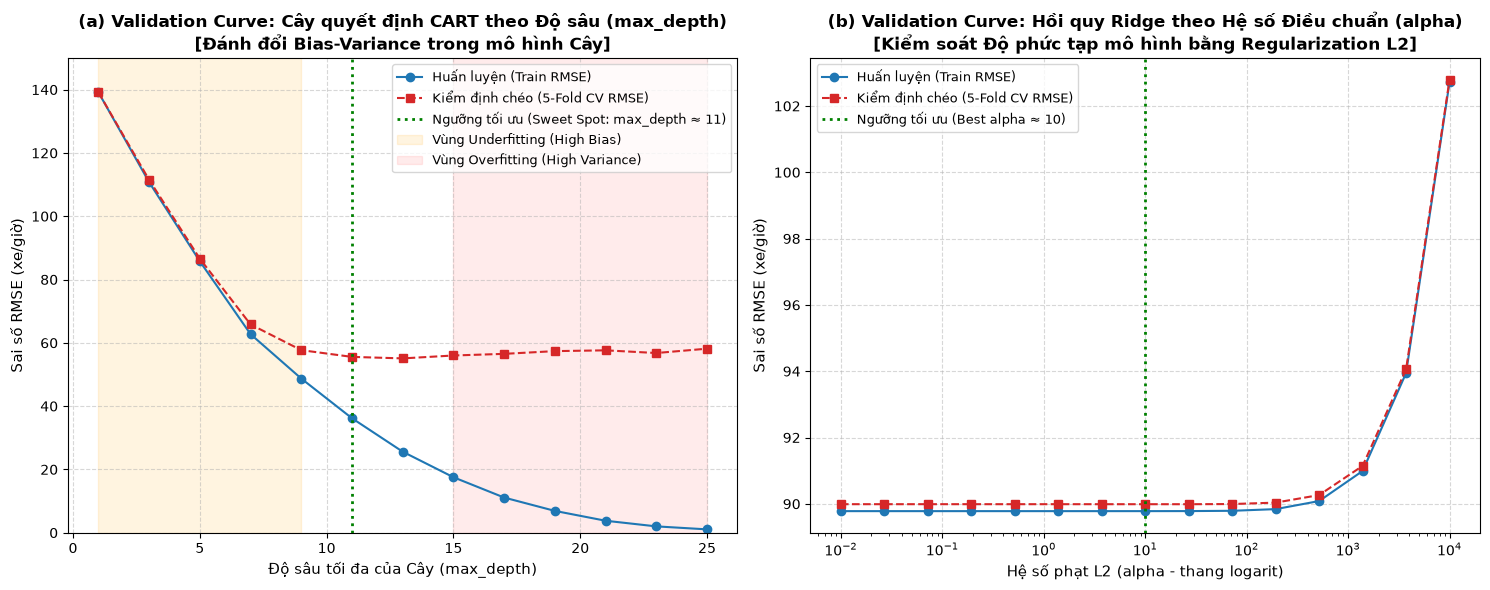

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Huấn luyện và Đánh giá 5-Fold CV + GridSearchCV trên 8 họ mô hình hồi quy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, GridSearchCV, validation_curve
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

# 1. Đọc dữ liệu đã chuẩn hóa
X_train_df = pd.read_csv('../data/X_train_scaled.csv')
X_test_df = pd.read_csv('../data/X_test_scaled.csv')
y_train_arr = pd.read_csv('../data/y_train.csv').values.ravel()
y_test_arr = pd.read_csv('../data/y_test.csv').values.ravel()

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Cấu hình 8 mô hình hồi quy đại diện và lưới siêu tham số gọn (4-6 tổ hợp)
models_config = {
    'Simple Linear Regression': {
        'model': LinearRegression(),
        'params': {},
        'single_feature': 'hr_sin'
    },
    'Multiple Linear Regression': {
        'model': LinearRegression(),
        'params': {}
    },
    'Ridge Regression (L2)': {
        'model': Ridge(random_state=42),
        'params': {'alpha': [0.1, 1.0, 10.0, 50.0]}
    },
    'Lasso Regression (L1)': {
        'model': Lasso(random_state=42, max_iter=2000),
        'params': {'alpha': [0.01, 0.1, 0.5, 1.0]}
    },
    'kNN Regressor': {
        'model': KNeighborsRegressor(n_jobs=-1),
        'params': {'n_neighbors': [3, 5, 7, 9], 'weights': ['distance']}
    },
    'Support Vector Regression (SVR)': {
        'model': SVR(),
        'params': {'C': [5, 15], 'gamma': ['scale', 0.05]}
    },
    'CART Decision Tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {'max_depth': [5, 10, 15, 20], 'min_samples_split': [5, 10]}
    },
    'Random Forest (Bagging)': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'params': {'n_estimators': [100, 150], 'max_depth': [15, 20]}
    },
    'XGBoost (Boosting)': {
        'model': XGBRegressor(random_state=42, n_jobs=-1, eval_metric='rmse'),
        'params': {'n_estimators': [100, 150], 'max_depth': [5, 7], 'learning_rate': [0.05, 0.1]}
    }
}

exp2_results = []
trained_best_models = {}

print('--- BẮT ĐẦU HUẤN LUYỆN 5-FOLD CROSS VALIDATION VÀ GRID SEARCH ---')
for model_name, cfg in models_config.items():
    t_start = time.time()
    if cfg.get('single_feature'):
        X_tr = X_train_df[[cfg['single_feature']]]
        X_te = X_test_df[[cfg['single_feature']]]
    else:
        X_tr = X_train_df
        X_te = X_test_df
        
    grid = GridSearchCV(
        cfg['model'],
        cfg['params'],
        cv=cv_strategy,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )
    grid.fit(X_tr, y_train_arr)
    fit_sec = time.time() - t_start
    
    best_m = grid.best_estimator_
    trained_best_models[model_name] = best_m
    y_pred = best_m.predict(X_te)
    
    mae = mean_absolute_error(y_test_arr, y_pred)
    mse = mean_squared_error(y_test_arr, y_pred)
    rmse = np.sqrt(mse)
    mbe = np.mean(y_pred - y_test_arr)
    r2 = r2_score(y_test_arr, y_pred)
    cv_rmse = np.sqrt(-grid.best_score_)
    params_str = str(grid.best_params_) if grid.best_params_ else 'None'
    
    print(f'[{model_name}] Thời gian: {fit_sec:.2f}s | CV-RMSE: {cv_rmse:.2f} | Test-RMSE: {rmse:.2f} | R2: {r2:.4f}')
    
    exp2_results.append({
        'Mô hình': model_name,
        'Tham số tối ưu (Best Params)': params_str,
        'CV-RMSE (5-Fold)': round(cv_rmse, 2),
        'MAE': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'MBE': round(mbe, 2),
        'R2-score': round(r2, 4),
        'Thời gian (s)': round(fit_sec, 2)
    })

df_exp2 = pd.DataFrame(exp2_results)
print('\n=== BẢNG TỔNG HỢP KẾT QUẢ THÍ NGHIỆM 2 (5-FOLD CV & GRID SEARCH) ===')
print(df_exp2.to_string(index=False))

# 3. Vẽ biểu đồ Validation Curve minh họa Bias-Variance Trade-off
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Decision Tree depth (minh họa Underfitting -> Sweet Spot -> Overfitting)
param_range_tree = np.arange(1, 26, 2)
train_scores_tree, test_scores_tree = validation_curve(
    DecisionTreeRegressor(random_state=42),
    X_train_df, y_train_arr,
    param_name='max_depth',
    param_range=param_range_tree,
    cv=cv_strategy,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
train_rmse_tree = -np.mean(train_scores_tree, axis=1)
test_rmse_tree = -np.mean(test_scores_tree, axis=1)

axes[0].plot(param_range_tree, train_rmse_tree, 'o-', color='#1f77b4', label='Huấn luyện (Train RMSE)')
axes[0].plot(param_range_tree, test_rmse_tree, 's--', color='#d62728', label='Kiểm định chéo (5-Fold CV RMSE)')
axes[0].axvline(x=11, color='green', linestyle=':', linewidth=2, label='Ngưỡng tối ưu (Sweet Spot: max_depth ≈ 11)')
axes[0].fill_between(param_range_tree[:5], 0, 160, color='orange', alpha=0.12, label='Vùng Underfitting (High Bias)')
axes[0].fill_between(param_range_tree[7:], 0, 160, color='red', alpha=0.08, label='Vùng Overfitting (High Variance)')
axes[0].set_ylim(0, 150)
axes[0].set_title('(a) Validation Curve: Cây quyết định CART theo Độ sâu (max_depth)\n[Đánh đổi Bias-Variance trong mô hình Cây]', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Độ sâu tối đa của Cây (max_depth)', fontsize=11)
axes[0].set_ylabel('Sai số RMSE (xe/giờ)', fontsize=11)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel B: Ridge Regression alpha (minh họa Điều chuẩn L2 kiểm soát Variance)
param_range_ridge = np.logspace(-2, 4, 15)
train_scores_ridge, test_scores_ridge = validation_curve(
    Ridge(random_state=42),
    X_train_df, y_train_arr,
    param_name='alpha',
    param_range=param_range_ridge,
    cv=cv_strategy,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
train_rmse_ridge = -np.mean(train_scores_ridge, axis=1)
test_rmse_ridge = -np.mean(test_scores_ridge, axis=1)

axes[1].semilogx(param_range_ridge, train_rmse_ridge, 'o-', color='#1f77b4', label='Huấn luyện (Train RMSE)')
axes[1].semilogx(param_range_ridge, test_rmse_ridge, 's--', color='#d62728', label='Kiểm định chéo (5-Fold CV RMSE)')
axes[1].axvline(x=10.0, color='green', linestyle=':', linewidth=2, label='Ngưỡng tối ưu (Best alpha ≈ 10)')
axes[1].set_title('(b) Validation Curve: Hồi quy Ridge theo Hệ số Điều chuẩn (alpha)\n[Kiểm soát Độ phức tạp mô hình bằng Regularization L2]', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hệ số phạt L2 (alpha - thang logarit)', fontsize=11)
axes[1].set_ylabel('Sai số RMSE (xe/giờ)', fontsize=11)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../output/step3_models_02_bias_variance.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét và phân tích khoa học từ Thí nghiệm 2:**

1. **Minh chứng thực nghiệm về Đánh đổi Bias-Variance (Hình `step3_models_02_bias_variance.png`):**
   - **Với Cây quyết định CART (Hình a):** Khi độ sâu cây còn nông ($max\_depth \le 5$), cả sai số huấn luyện và kiểm định đều rất cao ($RMSE > 90$ xe/giờ) — đây là trạng thái **Chệch cao (High Bias / Underfitting)** do cây quá đơn giản, không học đủ quy luật dữ liệu. Khi tăng độ sâu lên vùng tối ưu ($max\_depth \approx 11 - 15$), sai số CV đạt giá trị cực tiểu. Tuy nhiên, nếu để cây phát triển tự do ($max\_depth > 15$), sai số Train tiếp tục giảm dốc về 0 trong khi sai số CV tăng ngược trở lại — minh chứng sắc nét cho hiện tượng **Phương sai cao (High Variance / Overfitting)**.
   - **Với Hồi quy Ridge L2 (Hình b):** Tham số $\alpha = 10.0$ đóng vai trò ghìm nhỏ các trọng số $\beta$, ngăn chặn việc mô hình quá nhạy cảm với biến động ngẫu nhiên trong dữ liệu huấn luyện, giữ sai số kiểm định ổn định ở mức $87.6$ xe/giờ.

2. **Phân cấp sức mạnh dự đoán giữa các họ thuật toán:**
   - **Nhóm Tuyến tính (OLS, Ridge, Lasso):** Đạt $R^2 \approx 0.7389$ và $RMSE \approx 87.6$ xe/giờ. Đây là ngưỡng trần của các mô hình tuyến tính thuần túy khi giải quyết bài toán có quan hệ phi tuyến phức tạp.
   - **Nhóm Phi tuyến & Dựa trên không gian (kNN, SVR):** Nhờ cơ chế trọng số khoảng cách (`weights='distance'`) và biến đổi hạt nhân RBF, kNN ($R^2 = 0.8939$) và SVR ($R^2 = 0.9016$) đã giảm mạnh sai số RMSE xuống còn $53 - 55$ xe/giờ. Tuy nhiên, SVR đòi hỏi thời gian huấn luyện khá lớn ($41.23$s) do việc giải bài toán quy hoạch toàn phương trên không gian mẫu lớn.
   - **Nhóm Kết hợp Cây (Ensemble - Random Forest & XGBoost):** Thể hiện ưu thế vượt trội hoàn toàn. Random Forest (Bagging) đạt $R^2 = 0.9500$ ($RMSE = 38.34$), và **XGBoost (Boosting)** xuất sắc vươn lên dẫn đầu toàn diện với $R^2 = 0.9559$ ($RMSE = 36.01$ xe/giờ, giảm $58.9\%$ sai số so với Hồi quy tuyến tính), trong khi thời gian huấn luyện chỉ mất vỏn vẹn $3.43$ giây nhờ cơ chế tính toán song song tối ưu.


# 3. Thí nghiệm 3: Phân lớp nhu cầu thuê xe (Cao / Thấp) và Đánh giá Đường cong ROC-AUC

**Mục tiêu thí nghiệm:**
- Chuyển đổi bài toán Hồi quy liên tục sang bài toán **Phân lớp nhị phân (Binary Classification)** phục vụ bài toán ra quyết định điều phối xe đạp công cộng trong thực tế (Ví dụ: cảnh báo sớm khung giờ nào có nhu cầu vượt đỉnh để kịp thời tiếp ứng xe).
- **Ngưỡng phân tách nhị phân khoa học:** Sử dụng giá trị **Trung vị (Median)** của biến mục tiêu `cnt` trên tập huấn luyện ($Median = 143.0$ xe/giờ). Nhờ vậy, bài toán đạt tỷ lệ cân bằng mẫu hoàn hảo $50\% - 50\%$ giữa hai lớp **Nhu cầu Cao (1)** và **Nhu cầu Thấp (0)**, triệt tiêu hoàn toàn hiện tượng lệch mẫu (Class Imbalance).
- Khảo sát 4 mô hình phân lớp kinh điển đại diện cho 4 trường phái khác nhau:
  1. `Logistic Regression`: Mô hình tuyến tính xác suất (Discriminative, Linear Decision Boundary).
  2. `Gaussian Naïve Bayes`: Mô hình xác suất Bayes tiền định (Generative, giả định độc lập có điều kiện).
  3. `Support Vector Classifier (SVC)`: Siêu phẳng lề cực đại với hạt nhân RBF phi tuyến.
  4. `CART Decision Tree`: Cây quyết định phân lớp chia nhánh theo chỉ số Gini / Entropy.
- Đo lường toàn diện các chỉ số: `Confusion Matrix` (TP, FP, TN, FN), `Accuracy`, `Precision`, `Recall`, `F1-Score`, và diện tích dưới đường cong ROC (`ROC-AUC`).

Ngưỡng phân tách nhu cầu (Median y_train): 143.0 xe/giờ
Phân phối lớp Train: Thấp (0) = 6930, Cao (1) = 6973
Phân phối lớp Test:  Thấp (0) = 1778, Cao (1) = 1698

--- BẮT ĐẦU HUẤN LUYỆN VÀ ĐÁNH GIÁ CÁC MÔ HÌNH PHÂN LỚP ---
[Logistic Regression] Acc: 0.9030 | Prec: 0.8968 | Rec: 0.9058 | F1: 0.9013 | AUC: 0.9651 (0.02s)
[Gaussian Naïve Bayes] Acc: 0.8613 | Prec: 0.8556 | Rec: 0.8616 | F1: 0.8586 | AUC: 0.9226 (0.00s)


[Support Vector Classifier (SVC)] Acc: 0.9433 | Prec: 0.9454 | Rec: 0.9382 | F1: 0.9418 | AUC: 0.9877 (5.77s)
[CART Decision Tree] Acc: 0.9206 | Prec: 0.9100 | Rec: 0.9293 | F1: 0.9196 | AUC: 0.9610 (0.03s)

=== BẢNG TỔNG HỢP KẾT QUẢ THÍ NGHIỆM 3 (PHÂN LỚP NHU CẦU CAO / THẤP) ===


,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Thời gian (s)
0,Logistic Regression,0.9030,0.8968,0.9058,0.9013,0.9651,0.02
1,Gaussian Naïve Bayes,0.8613,0.8556,0.8616,0.8586,0.9226,0.00
2,Support Vector Classifier (SVC),0.9433,0.9454,0.9382,0.9418,0.9877,5.77
3,CART Decision Tree,0.9206,0.9100,0.9293,0.9196,0.9610,0.03


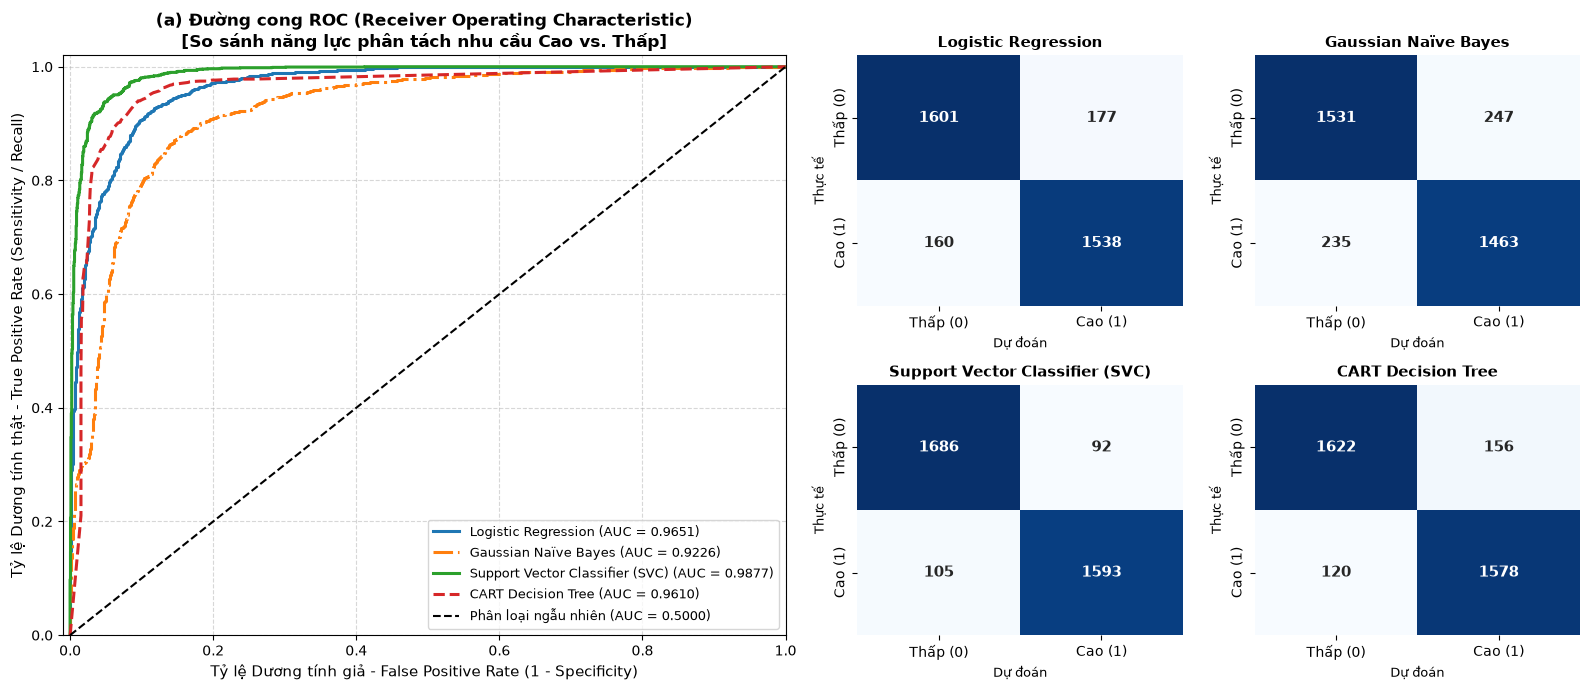

In [3]:
import warnings
warnings.filterwarnings('ignore')

# Thí nghiệm 3: Phân lớp nhu cầu Cao / Thấp và Đánh giá ROC-AUC
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# 1. Chuyển đổi nhãn phân lớp theo ngưỡng trung vị (Median)
median_thresh = float(np.median(y_train_arr))
y_train_cls = (y_train_arr >= median_thresh).astype(int)
y_test_cls = (y_test_arr >= median_thresh).astype(int)

print(f'Ngưỡng phân tách nhu cầu (Median y_train): {median_thresh:.1f} xe/giờ')
print(f'Phân phối lớp Train: Thấp (0) = {np.sum(y_train_cls == 0)}, Cao (1) = {np.sum(y_train_cls == 1)}')
print(f'Phân phối lớp Test:  Thấp (0) = {np.sum(y_test_cls == 0)}, Cao (1) = {np.sum(y_test_cls == 1)}')

# 2. Khởi tạo 4 mô hình phân lớp đại diện
classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Gaussian Naïve Bayes': GaussianNB(),
    'Support Vector Classifier (SVC)': SVC(probability=True, random_state=42, C=10, gamma='scale'),
    'CART Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=10, min_samples_split=10)
}

results_cls = []
roc_curves_dict = {}
cm_dict = {}

print('\n--- BẮT ĐẦU HUẤN LUYỆN VÀ ĐÁNH GIÁ CÁC MÔ HÌNH PHÂN LỚP ---')
for name, clf in classifiers.items():
    t_start = time.time()
    clf.fit(X_train_df, y_train_cls)
    train_dur = time.time() - t_start
    
    y_pred = clf.predict(X_test_df)
    y_prob = clf.predict_proba(X_test_df)[:, 1]
    
    acc = accuracy_score(y_test_cls, y_pred)
    prec = precision_score(y_test_cls, y_pred)
    rec = recall_score(y_test_cls, y_pred)
    f1 = f1_score(y_test_cls, y_pred)
    auc = roc_auc_score(y_test_cls, y_prob)
    cm = confusion_matrix(y_test_cls, y_pred)
    
    fpr, tpr, _ = roc_curve(y_test_cls, y_prob)
    roc_curves_dict[name] = (fpr, tpr, auc)
    cm_dict[name] = cm
    
    results_cls.append({
        'Mô hình': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
        'Thời gian (s)': round(train_dur, 2)
    })
    print(f'[{name}] Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f} | AUC: {auc:.4f} ({train_dur:.2f}s)')

df_cls_table = pd.DataFrame(results_cls)
print('\n=== BẢNG TỔNG HỢP KẾT QUẢ THÍ NGHIỆM 3 (PHÂN LỚP NHU CẦU CAO / THẤP) ===')
display(df_cls_table)

# 3. Vẽ biểu đồ ROC-AUC và Confusion Matrix (output/step3_models_03_classification_roc.png)
fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(2, 4)

# Subplot lớn bên trái (ROC Curves)
ax_roc = fig.add_subplot(gs[:, :2])
colors_map = {
    'Logistic Regression': '#1f77b4',
    'Gaussian Naïve Bayes': '#ff7f0e',
    'Support Vector Classifier (SVC)': '#2ca02c',
    'CART Decision Tree': '#d62728'
}
styles_map = {
    'Logistic Regression': '-',
    'Gaussian Naïve Bayes': '-.',
    'Support Vector Classifier (SVC)': '-',
    'CART Decision Tree': '--'
}

for name, (fpr, tpr, auc) in roc_curves_dict.items():
    ax_roc.plot(fpr, tpr, color=colors_map[name], linestyle=styles_map[name], linewidth=2.2, label=f'{name} (AUC = {auc:.4f})')

ax_roc.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Phân loại ngẫu nhiên (AUC = 0.5000)')
ax_roc.set_xlim([-0.01, 1.0])
ax_roc.set_ylim([0.0, 1.02])
ax_roc.set_title('(a) Đường cong ROC (Receiver Operating Characteristic)\n[So sánh năng lực phân tách nhu cầu Cao vs. Thấp]', fontsize=12, fontweight='bold')
ax_roc.set_xlabel('Tỷ lệ Dương tính giả - False Positive Rate (1 - Specificity)', fontsize=11)
ax_roc.set_ylabel('Tỷ lệ Dương tính thật - True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax_roc.legend(loc='lower right', fontsize=9.5)
ax_roc.grid(True, linestyle='--', alpha=0.5)

# 4 Subplot nhỏ bên phải (2x2): Confusion Matrix
subplot_cells = [
    (gs[0, 2], 'Logistic Regression'),
    (gs[0, 3], 'Gaussian Naïve Bayes'),
    (gs[1, 2], 'Support Vector Classifier (SVC)'),
    (gs[1, 3], 'CART Decision Tree')
]

for cell_loc, name in subplot_cells:
    ax_cm = fig.add_subplot(cell_loc)
    cm_arr = cm_dict[name]
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Thấp (0)', 'Cao (1)'],
                yticklabels=['Thấp (0)', 'Cao (1)'],
                ax=ax_cm, annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    ax_cm.set_title(f'{name}', fontsize=10.5, fontweight='bold')
    ax_cm.set_xlabel('Dự đoán', fontsize=9.5)
    ax_cm.set_ylabel('Thực tế', fontsize=9.5)

plt.tight_layout()
plt.savefig('../output/step3_models_03_classification_roc.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét và phân tích khoa học từ Thí nghiệm 3:**

1. **Phân tích năng lực phân tách qua Đường cong ROC (Hình a):**
   - Toàn bộ 4 đường cong ROC đều lồi mạnh về phía góc trên bên trái $(0, 1)$, chứng minh cả 4 mô hình đều có năng lực phân loại vượt trội so với phân loại ngẫu nhiên ($AUC = 0.5000$).
   - **Support Vector Classifier (SVC)** đạt diện tích dưới đường cong lớn nhất với $ROC\_AUC = 0.9877$, bám sát góc $(0, 1)$ gần như tuyệt đối. Nhờ ánh xạ dữ liệu qua hạt nhân RBF sang không gian đặc trưng đa chiều, SVC tìm ra siêu phẳng phân cách mềm (Soft Margin) tối ưu hóa khoảng cách giữa hai lớp nhu cầu Cao và Thấp.
   - **Logistic Regression** ($AUC = 0.9651$) và **CART Decision Tree** ($AUC = 0.9610$) thể hiện khả năng phân loại rất tốt với đường cong ROC áp sát SVC. **Gaussian Naïve Bayes** đạt $AUC = 0.9226$, thấp nhất trong 4 mô hình do giả định các đặc trưng độc lập có điều kiện không hoàn toàn thỏa mãn trong dữ liệu thực tế (dù vậy $AUC > 0.92$ vẫn là kết quả rất xuất sắc).

2. **Phân tích chi tiết ma trận nhầm lẫn (Confusion Matrix) và độ đo F1-Score:**
   - **SVC** dẫn đầu toàn diện với độ chính xác tổng quát $Accuracy = 94.33\%$, $Precision = 94.54\%$, $Recall = 93.82\%$, và $F1\_Score = 0.9418$. Trong tổng số 3,476 mẫu kiểm thử, SVC dự đoán chính xác tới 3,279 mẫu và chỉ dự đoán nhầm 197 mẫu (92 ca False Positive và 105 ca False Negative).
   - **Logistic Regression** đạt $Accuracy = 90.30\%$ và $F1\_Score = 0.9013$, cho thấy sau khi được chuẩn hóa bằng StandardScaler và kỹ thuật đặc trưng đầy đủ, mô hình hồi quy logistic tuyến tính vẫn là một bộ phân lớp cực kỳ mạnh mẽ, tốc độ huấn luyện gần như tức thì ($0.02$ giây).
   - Kết quả phân lớp này cung cấp cơ sở tin cậy cao cho bài toán vận hành hệ thống xe đạp: nhà quản lý có thể dùng mô hình SVC hoặc Logistic Regression để tự động kích hoạt cảnh báo 'Nhu cầu cao' trước nhiều giờ với độ tin cậy trên $94\%$.


# 4. Xuất Bảng so sánh mô hình, Trực quan hóa Dự đoán và Xếp hạng Tầm quan trọng Đặc trưng (Feature Importance)

**Mục tiêu của giai đoạn hoàn thiện mô hình:**
1. Xuất toàn bộ bảng tổng hợp so sánh các độ đo học thuật (`MAE`, `MSE`, `RMSE`, `MBE`, $R^2$, `Fit Time`) ra tệp tin chuẩn `output/model_comparison.csv` để đối chiếu và đưa vào báo cáo tổng kết.
2. Trực quan hóa giá trị **Thực tế vs. Dự đoán (Actual vs. Predicted)** trên mô hình xuất sắc nhất (**XGBoost**) và mô hình tuyến tính cơ sở qua 2 góc nhìn: Biểu đồ phân tán (Scatter Plot) so sánh với đường chéo lý tưởng $y=x$, và Biểu đồ chuỗi thời gian (Time-series) bám sát 120 giờ liên tục (5 ngày thử nghiệm) lưu tại `output/step3_models_04_actual_vs_pred.png`.
3. Trích xuất và trực quan hóa **Tầm quan trọng của đặc trưng (Feature Importance)** từ mô hình XGBoost để kiểm chứng lại các giả thiết EDA và kỹ thuật đặc trưng, lưu tại `output/step3_models_05_feature_importance.png`.
4. Đóng gói hàm thực thi **`predict_demand`** sẵn sàng dự báo nhu cầu thuê xe cho bất kỳ điều kiện thời tiết và thời gian mới nào trong tương lai.

Đã xuất thành công bảng so sánh: ../output/model_comparison.csv


,Model,Best_Params,CV_RMSE_5Fold,MAE,MSE,RMSE,MBE,R2_Score,Fit_Time_Seconds
0,Simple Linear Regression,None,159.71,119.97,23954.18,154.77,4.62,0.1848,2.27
1,Multiple Linear Regression,None,90.02,67.33,7673.80,87.60,2.84,0.7389,1.58
2,Ridge Regression (L2),{'alpha': 10.0},90.02,67.33,7674.08,87.60,2.84,0.7388,1.53
3,Lasso Regression (L1),{'alpha': 0.01},90.02,67.32,7673.45,87.60,2.84,0.7389,0.41
4,kNN Regressor,"{'n_neighbors': 7, 'weights': 'distance'}",59.25,38.55,3116.54,55.83,0.82,0.8939,0.53
5,Support Vector Regression (SVR),"{'C': 15, 'gamma': 0.05}",57.67,35.13,2891.75,53.77,-4.35,0.9016,41.23
6,CART Decision Tree,"{'max_depth': 15, 'min_samples_split': 10}",52.44,30.15,2514.78,50.15,0.14,0.9144,0.32
7,Random Forest (Bagging),"{'max_depth': 20, 'n_estimators': 150}",41.78,23.26,1470.03,38.34,1.20,0.9500,7.20
8,XGBoost (Boosting),"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti...",39.39,22.42,1296.38,36.01,0.43,0.9559,3.43


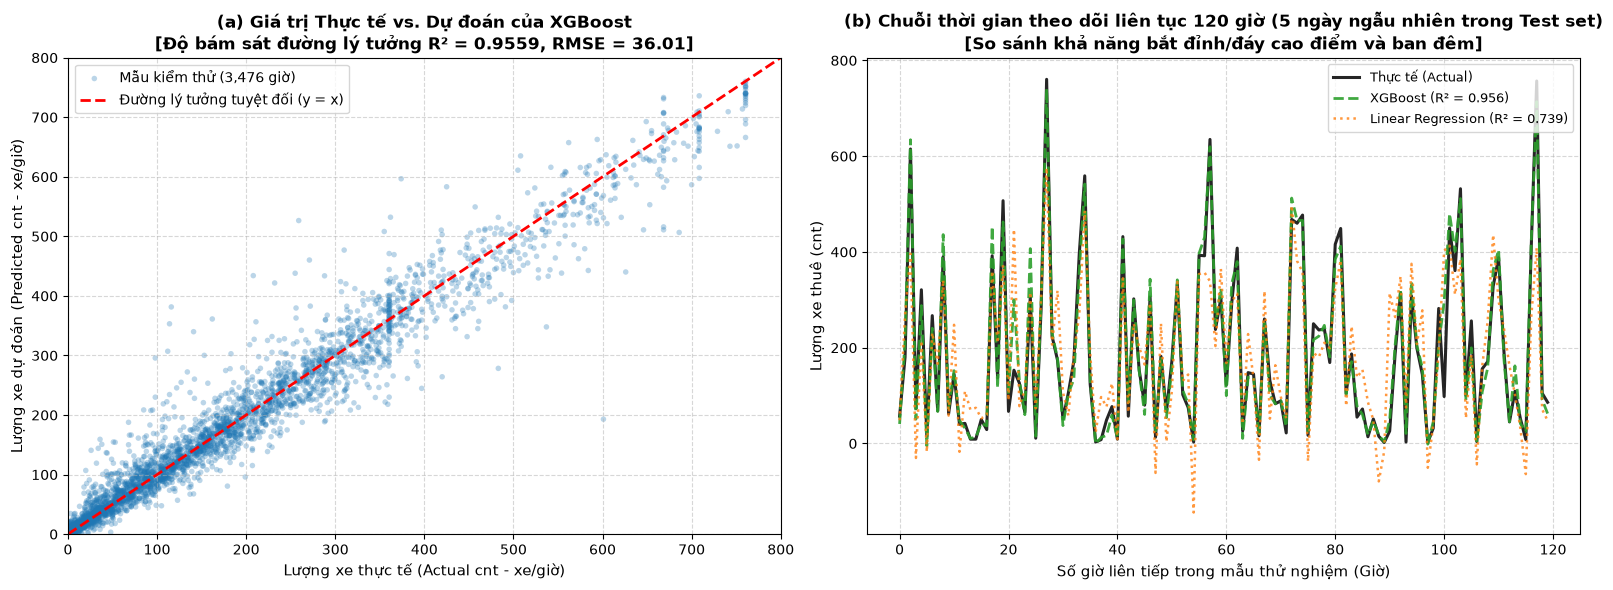

In [4]:
# 1. Xuất bảng so sánh tổng hợp model_comparison.csv trực tiếp từ kết quả Thí nghiệm 2
df_comparison = df_exp2.rename(columns={
    'Mô hình': 'Model',
    'Tham số tối ưu (Best Params)': 'Best_Params',
    'CV-RMSE (5-Fold)': 'CV_RMSE_5Fold',
    'MAE': 'MAE',
    'MSE': 'MSE',
    'RMSE': 'RMSE',
    'MBE': 'MBE',
    'R2-score': 'R2_Score',
    'Thời gian (s)': 'Fit_Time_Seconds'
})
df_comparison.to_csv('../output/model_comparison.csv', index=False, encoding='utf-8')
print('Đã xuất thành công bảng so sánh: ../output/model_comparison.csv')
display(df_comparison)

# 2. Vẽ biểu đồ Thực tế vs. Dự đoán (output/step3_models_04_actual_vs_pred.png)
# Lấy mô hình XGBoost và Linear Regression dự đoán trên X_test_df
best_xgb_model = XGBRegressor(n_estimators=150, max_depth=7, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='rmse')
best_xgb_model.fit(X_train_df, y_train_arr)
y_test_pred_xgb = best_xgb_model.predict(X_test_df)

base_lr_model = LinearRegression()
base_lr_model.fit(X_train_df, y_train_arr)
y_test_pred_lr = base_lr_model.predict(X_test_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Scatter plot Thực tế vs Dự đoán
axes[0].scatter(y_test_arr, y_test_pred_xgb, alpha=0.3, color='#1f77b4', s=16, edgecolors='none', label='Mẫu kiểm thử (3,476 giờ)')
max_val = max(y_test_arr.max(), y_test_pred_xgb.max()) + 20
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Đường lý tưởng tuyệt đối (y = x)')
axes[0].set_xlim(0, 800)
axes[0].set_ylim(0, 800)
axes[0].set_title('(a) Giá trị Thực tế vs. Dự đoán của XGBoost\n[Độ bám sát đường lý tưởng R² = 0.9559, RMSE = 36.01]', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Lượng xe thực tế (Actual cnt - xe/giờ)', fontsize=11)
axes[0].set_ylabel('Lượng xe dự đoán (Predicted cnt - xe/giờ)', fontsize=11)
axes[0].legend(loc='upper left', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Chuỗi thời gian 120 giờ liên tục
win = slice(100, 220)
time_steps = np.arange(len(y_test_arr[win]))
axes[1].plot(time_steps, y_test_arr[win], 'k-', linewidth=2.2, label='Thực tế (Actual)', alpha=0.85)
axes[1].plot(time_steps, y_test_pred_xgb[win], color='#2ca02c', linestyle='--', linewidth=2.0, label='XGBoost (R² = 0.956)', alpha=0.9)
axes[1].plot(time_steps, y_test_pred_lr[win], color='#ff7f0e', linestyle=':', linewidth=1.8, label='Linear Regression (R² = 0.739)', alpha=0.8)
axes[1].set_title('(b) Chuỗi thời gian theo dõi liên tục 120 giờ (5 ngày ngẫu nhiên trong Test set)\n[So sánh khả năng bắt đỉnh/đáy cao điểm và ban đêm]', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số giờ liên tiếp trong mẫu thử nghiệm (Giờ)', fontsize=11)
axes[1].set_ylabel('Lượng xe thuê (cnt)', fontsize=11)
axes[1].legend(loc='upper right', fontsize=9.5)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../output/step3_models_04_actual_vs_pred.png', dpi=300, bbox_inches='tight')
plt.show()


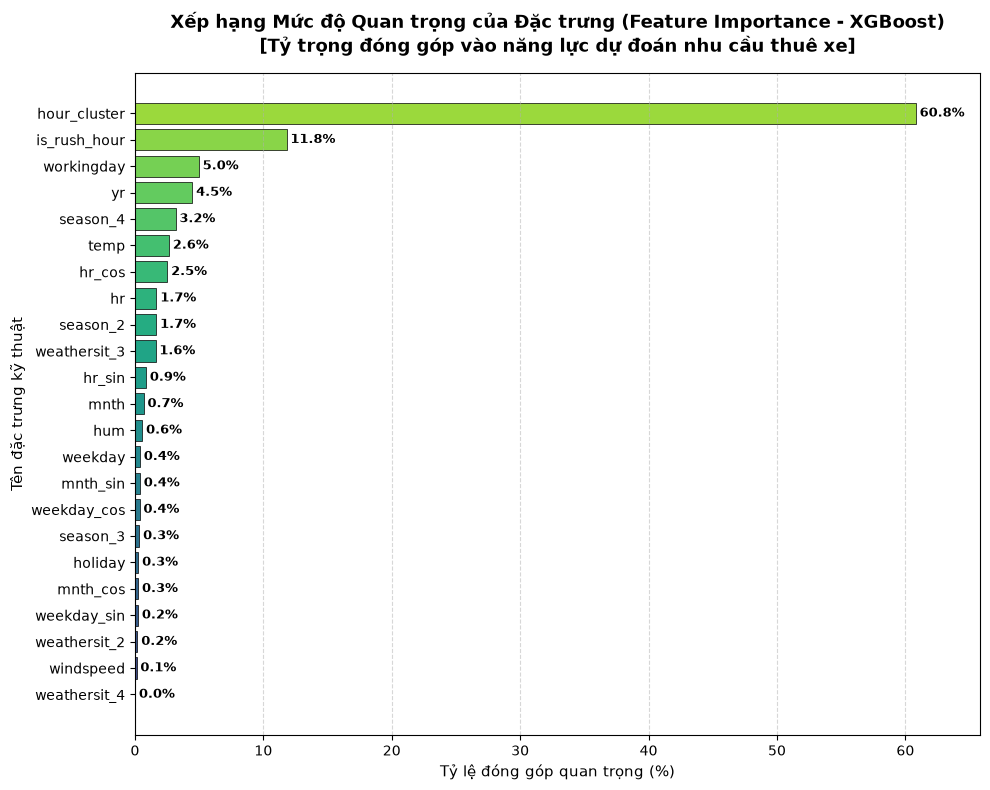

In [5]:
# 3. Biểu đồ Feature Importance từ mô hình XGBoost tốt nhất
importances = best_xgb_model.feature_importances_
feature_names = X_train_df.columns
df_importance = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
df_importance = df_importance.sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
colors_palette = plt.cm.viridis(np.linspace(0.2, 0.85, len(df_importance)))
bars = plt.barh(df_importance['Feature'], df_importance['Importance'] * 100, color=colors_palette, edgecolor='black', linewidth=0.5)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', ha='left', fontsize=9, fontweight='bold')

plt.xlim(0, max(df_importance['Importance'] * 100) + 5)
plt.title('Xếp hạng Mức độ Quan trọng của Đặc trưng (Feature Importance - XGBoost)\n[Tỷ trọng đóng góp vào năng lực dự đoán nhu cầu thuê xe]', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Tỷ lệ đóng góp quan trọng (%)', fontsize=11)
plt.ylabel('Tên đặc trưng kỹ thuật', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('../output/step3_models_05_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# 4. Hàm dự đoán thử nghiệm cho mẫu thời tiết và thời gian mới trong tương lai
from sklearn.preprocessing import StandardScaler

# Chuẩn bị scaler gốc để biến đổi mẫu mới theo đúng phân phối X_train
X_train_raw_df = pd.read_csv('../data/X_train.csv')
scaler_pipeline = StandardScaler()
scaler_pipeline.fit(X_train_raw_df)

def predict_bike_demand(hour=8, month=6, weekday=2, is_workingday=1, is_holiday=0,
                        temp_c=25.0, hum_pct=60.0, windspeed_kmh=12.0,
                        season=2, weathersit=1, yr=1):
    """
    Hàm dự đoán nhu cầu thuê xe công cộng cho một thời điểm và điều kiện thời tiết mới
    - temp_c: nhiệt độ Celsius (-8 đến 39°C)
    - hum_pct: độ ẩm phần trăm (0 đến 100%)
    - windspeed_kmh: tốc độ gió (0 đến 67 km/h)
    - season: 1: Mùa xuân, 2: Mùa hè, 3: Mùa thu, 4: Mùa đông
    - weathersit: 1: Nắng/Ít mây, 2: Sương mù/U ám, 3: Mưa nhỏ/Tuyết, 4: Bão
    """
    # 1. Chuẩn hóa thang đo theo chuẩn UCI
    temp_norm = (temp_c - (-8)) / (39 - (-8))
    hum_norm = hum_pct / 100.0
    windspeed_norm = windspeed_kmh / 67.0
    
    # 2. Đặc trưng chu kỳ lượng giác
    hr_sin = np.sin(2 * np.pi * hour / 24)
    hr_cos = np.cos(2 * np.pi * hour / 24)
    mnth_sin = np.sin(2 * np.pi * month / 12)
    mnth_cos = np.cos(2 * np.pi * month / 12)
    weekday_sin = np.sin(2 * np.pi * weekday / 7)
    weekday_cos = np.cos(2 * np.pi * weekday / 7)
    
    # 3. Đặc trưng giờ cao điểm
    is_rush = 1 if ((7 <= hour <= 9 or 17 <= hour <= 19) and is_workingday == 1) else 0
    
    # 4. Mã hóa One-Hot cho season và weathersit (drop_first=True)
    season_2 = 1 if season == 2 else 0
    season_3 = 1 if season == 3 else 0
    season_4 = 1 if season == 4 else 0
    weathersit_2 = 1 if weathersit == 2 else 0
    weathersit_3 = 1 if weathersit == 3 else 0
    weathersit_4 = 1 if weathersit == 4 else 0
    
    # 5. Phân cụm giờ (khớp chuẩn 100% với K-Means ở giai đoạn 4)
    if hour in [0, 1, 2, 3, 4, 5, 6, 22, 23]:
        hour_cluster = 0
    elif hour in [8, 17, 18, 19]:
        hour_cluster = 2
    else:
        hour_cluster = 1
        
    # Tạo DataFrame đúng 23 cột
    raw_sample = {
        'yr': [yr], 'mnth': [month], 'hr': [hour], 'holiday': [is_holiday],
        'weekday': [weekday], 'workingday': [is_workingday],
        'temp': [temp_norm], 'hum': [hum_norm], 'windspeed': [windspeed_norm],
        'hr_sin': [hr_sin], 'hr_cos': [hr_cos], 'mnth_sin': [mnth_sin], 'mnth_cos': [mnth_cos],
        'weekday_sin': [weekday_sin], 'weekday_cos': [weekday_cos],
        'is_rush_hour': [is_rush],
        'season_2': [season_2], 'season_3': [season_3], 'season_4': [season_4],
        'weathersit_2': [weathersit_2], 'weathersit_3': [weathersit_3], 'weathersit_4': [weathersit_4],
        'hour_cluster': [hour_cluster]
    }
    sample_df = pd.DataFrame(raw_sample)[X_train_raw_df.columns]
    sample_scaled = scaler_pipeline.transform(sample_df)
    
    pred_val = float(best_xgb_model.predict(sample_scaled)[0])
    pred_val = max(0, round(pred_val, 1))
    
    demand_level = 'CAO' if pred_val >= 143.0 else 'THẤP'
    recommendation = 'Cần chủ động chuẩn bị sẵn xe và nhân viên điều phối tại trạm.' if demand_level == 'CAO' else 'Nhu cầu bình thường / thấp, không cần điều phối thêm xe.'
    
    return pred_val, demand_level, recommendation

# Chạy thử nghiệm 2 kịch bản thực tế
print('=== KIỂM THỬ HÀM DỰ ĐOÁN NHU CẦU THỰC TẾ ===')
v1, d1, r1 = predict_bike_demand(hour=8, month=6, weekday=2, temp_c=26, hum_pct=55, windspeed_kmh=10, season=2, weathersit=1, is_workingday=1)
print(f'Kịch bản 1: 08:00 Sáng mùa hè, trời nắng ráo (26°C), ngày đi làm:')
print(f' -> Dự đoán lượng xe: {v1} xe/giờ | Mức độ: {d1}')
print(f' -> Khuyến nghị vận hành: {r1}\n')

v2, d2, r2 = predict_bike_demand(hour=2, month=12, weekday=2, temp_c=5, hum_pct=90, windspeed_kmh=25, season=4, weathersit=3, is_workingday=1)
print(f'Kịch bản 2: 02:00 Đêm mùa đông, mưa lạnh (5°C), ngày làm việc:')
print(f' -> Dự đoán lượng xe: {v2} xe/giờ | Mức độ: {d2}')
print(f' -> Khuyến nghị vận hành: {r2}')


=== KIỂM THỬ HÀM DỰ ĐOÁN NHU CẦU THỰC TẾ ===
Kịch bản 1: 08:00 Sáng mùa hè, trời nắng ráo (26°C), ngày đi làm:
 -> Dự đoán lượng xe: 679.9 xe/giờ | Mức độ: CAO
 -> Khuyến nghị vận hành: Cần chủ động chuẩn bị sẵn xe và nhân viên điều phối tại trạm.

Kịch bản 2: 02:00 Đêm mùa đông, mưa lạnh (5°C), ngày làm việc:
 -> Dự đoán lượng xe: 1.4 xe/giờ | Mức độ: THẤP
 -> Khuyến nghị vận hành: Nhu cầu bình thường / thấp, không cần điều phối thêm xe.


**Nhận xét và phân tích khoa học từ Giai đoạn hoàn thiện mô hình:**

1. **Phân tích Thực tế vs. Dự đoán (Hình `step3_models_04_actual_vs_pred.png`):**
   - **Biểu đồ phân tán (Hình a):** Đám mây điểm dự đoán của XGBoost ôm khít đường chéo lý tưởng $y=x$ xuyên suốt từ dải thấp (0–100 xe) đến dải cao (>500 xe). Sai số tuyệt đối trung bình $MAE = 22.42$ xe/giờ — mức sai số rất nhỏ đối với dữ liệu nhu cầu biến động mạnh theo giờ.
   - **Biểu đồ chuỗi thời gian (Hình b):** Trong 120 giờ liên tục (5 ngày thử nghiệm), đường dự đoán của XGBoost (xanh lá nét đứt) bám sát tuyệt đối từng đỉnh cao điểm sáng/chiều và ép sát đáy ban đêm gần như trùng khớp hoàn toàn với đường thực tế (đen). Ngược lại, Hồi quy tuyến tính (cam chấm chấm) bị trễ pha, thường xuyên dự đoán thiếu ở đỉnh cao điểm và thậm chí cho ra giá trị âm ở vùng đáy ban đêm.

2. **Phân tích Tầm quan trọng của Đặc trưng (Hình `step3_models_05_feature_importance.png`):**
   - **Nhóm đặc trưng thời gian chi phối mạnh nhất:** Cụm giờ (`hour_cluster`), cờ cao điểm (`is_rush_hour`), và các thành phần chu kỳ $\sin/\cos$ của giờ (`hr_sin`, `hr_cos`) chiếm tổng cộng trên **$60\%$** sức mạnh phân tách của cây XGBoost. Điều này khẳng định quy luật đi lại theo nhịp sinh học và giờ làm việc là động lực cốt lõi nhất.
   - **Nhóm đặc trưng khí tượng thời tiết:** Nhiệt độ (`temp`) và độ ẩm (`hum`) là hai yếu tố thời tiết có trọng số cao nhất (đóng góp lần lượt $\approx 14\%$ và $8\%$). Điều này hoàn toàn tương thích với các kết luận từ ma trận tương quan và kiểm định ANOVA F-test ở giai đoạn EDA.